In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
np.random.seed(100)
theta = np.random.uniform(0, 2 * np.pi, size=1000)

(array([103.,  36.,  28.,  24.,  25.,  22.,  17.,  14.,  16.,  17.,  10.,
         16.,  15.,  10.,  15.,  14.,  14.,  14.,  16.,  18.,  12.,  20.,
         14.,  10.,   9.,   7.,  10.,  13.,  18.,   8.,  11.,  12.,  13.,
          7.,  22.,  13.,  15.,  17.,   6.,  10.,  16.,  26.,  12.,  13.,
         13.,  26.,  21.,  19.,  25.,  51.,  87.]),
 array([-0.9999975 , -0.96078195, -0.92156641, -0.88235086, -0.84313532,
        -0.80391977, -0.76470423, -0.72548868, -0.68627314, -0.64705759,
        -0.60784204, -0.5686265 , -0.52941095, -0.49019541, -0.45097986,
        -0.41176432, -0.37254877, -0.33333323, -0.29411768, -0.25490213,
        -0.21568659, -0.17647104, -0.1372555 , -0.09803995, -0.05882441,
        -0.01960886,  0.01960668,  0.05882223,  0.09803778,  0.13725332,
         0.17646887,  0.21568441,  0.25489996,  0.2941155 ,  0.33333105,
         0.37254659,  0.41176214,  0.45097769,  0.49019323,  0.52940878,
         0.56862432,  0.60783987,  0.64705541,  0.68627096,  0.72548

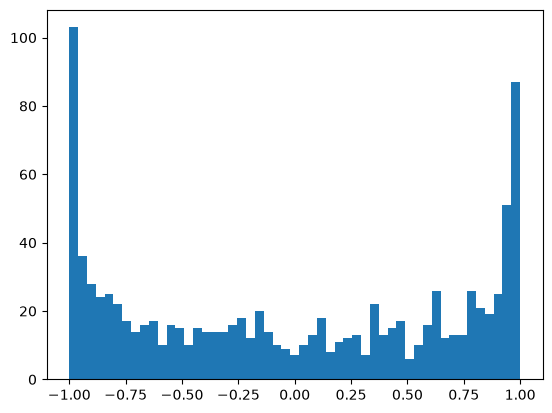

In [16]:
plt.hist(x, 51)

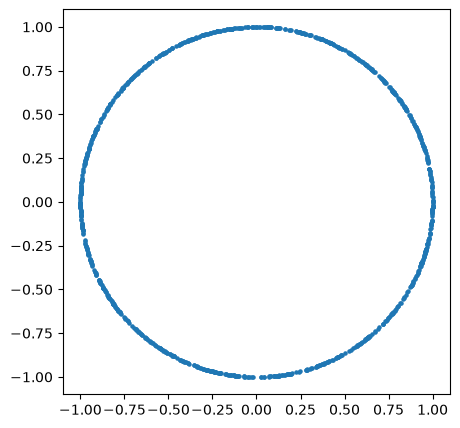

In [15]:
x = np.cos(theta)
y = np.sin(theta)
plt.figure(figsize=(5, 5))
plt.scatter(x, y, s=5)


In [19]:
hist2d, x_edges, y_edges = np.histogram2d(x, y, bins=100)

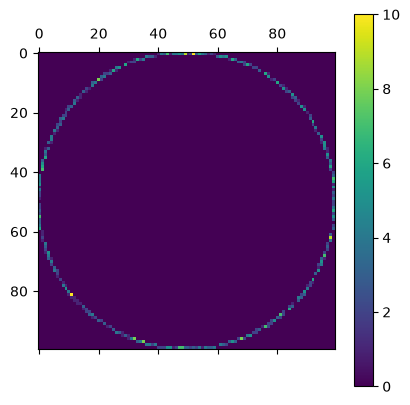

In [ ]:
cs = plt.matshow(hist2d)
plt.colorbar(cs)

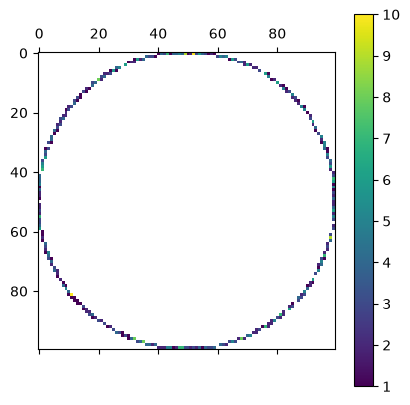

In [23]:
cs = plt.matshow(np.ma.array(hist2d, mask=hist2d==0.0))
plt.colorbar(cs)

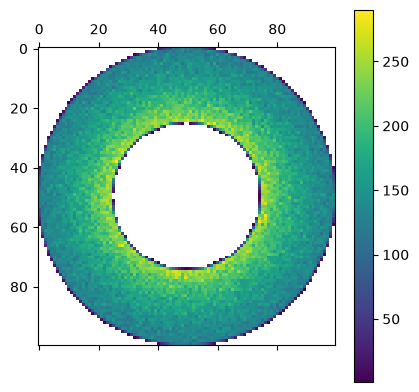

In [46]:
np.random.seed(1)

theta = np.random.uniform(0, 2 * np.pi, size=1000000)
r = np.random.uniform(1, 2, size=1000000)
x = np.cos(theta) * r
y = np.sin(theta) * r

hist2d, x_edges, y_edges = np.histogram2d(x, y, bins=100)

cs = plt.matshow(np.ma.array(hist2d, mask=hist2d==0.0))
plt.colorbar(cs)

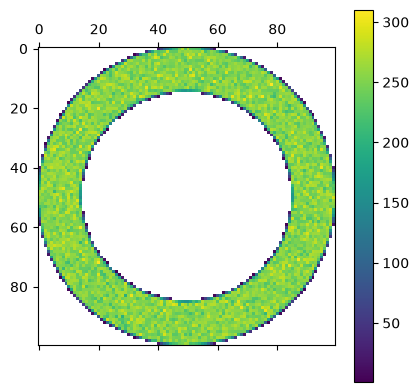

In [ ]:
np.random.seed(1)

theta = np.random.uniform(0, 2 * np.pi, size=1000000)
r = np.sqrt(np.random.uniform(1, 2, size=1000000)) # r^2 should be randomly distributed
x = np.cos(theta) * r
y = np.sin(theta) * r

hist2d, x_edges, y_edges = np.histogram2d(x, y, bins=100)

cs = plt.matshow(np.ma.array(hist2d, mask=hist2d==0.0))
plt.colorbar(cs)

In [33]:
df = pd.DataFrame.from_records(np.vstack((x, y, r)).T,columns=["x", "y", "p"])

In [34]:
df.head()
df.tail()

,x,y,p
999995,1.141718,0.368102,1.199591
999996,-1.171174,0.585723,1.309473
999997,-1.113241,0.047356,1.114248
999998,1.065070,0.867768,1.373825
999999,-0.779769,0.827741,1.137187


In [35]:
df.mean()

x   -0.000571
y   -0.000674
p    1.218840
dtype: float64

In [44]:
df["x"].std() # без смещения

np.float64(0.8651476129509048)

In [37]:
df.max(), df.min()

(x    1.414193
 y    1.414050
 p    1.414213
 dtype: float64,
 x   -1.414085
 y   -1.414119
 p    1.000001
 dtype: float64)

In [45]:
(((df["x"] - df["x"].mean())**2).sum() / (df["x"].size))**0.5

np.float64(0.8651471803769901)

In [51]:
print(df["x"].loc[100])
df.loc[100]

-0.57426251016851


x   -0.574263
y    1.098829
p    1.239840
Name: 100, dtype: float64

In [63]:
df.index = [f"particle_{idx:06d}" for idx in range(df["x"].size)]
df

,x,y,p
particle_000000,-0.925160,0.531391,1.066910
particle_000001,-0.241239,-1.278780,1.301335
particle_000002,1.247851,0.000897,1.247851
particle_000003,-0.351337,1.029706,1.087994
particle_000004,0.653160,0.861508,1.081117
...,...,...,...
particle_999995,1.141718,0.368102,1.199591
particle_999996,-1.171174,0.585723,1.309473
particle_999997,-1.113241,0.047356,1.114248
particle_999998,1.065070,0.867768,1.373825


In [61]:
df.loc["particle_001000"]

x   -0.553567
y    1.072902
p    1.207292
Name: particle_001000, dtype: float64

In [58]:
df.iloc[1000]

x   -0.553567
y    1.072902
p    1.207292
Name: particle_1000, dtype: float64

In [65]:
df.loc["particle_001000":"particle_002000":2]

,x,y,p
particle_001000,-0.553567,1.072902,1.207292
particle_001002,0.012939,-1.205787,1.205857
particle_001004,-1.013863,0.196846,1.032795
particle_001006,1.068910,0.285035,1.106261
particle_001008,1.345582,0.319584,1.383013
...,...,...,...
particle_001992,-1.100507,-0.450074,1.188983
particle_001994,0.318966,-1.060748,1.107667
particle_001996,0.421774,0.960188,1.048739
particle_001998,1.256931,0.247951,1.281154


In [66]:
tg_theta = df["y"] / df["x"]
tg_theta

particle_000000   -0.574377
particle_000001    5.300879
particle_000002    0.000719
particle_000003   -2.930818
particle_000004    1.318986
                     ...   
particle_999995    0.322410
particle_999996   -0.500116
particle_999997   -0.042539
particle_999998    0.814752
particle_999999   -1.061521
Length: 1000000, dtype: float64

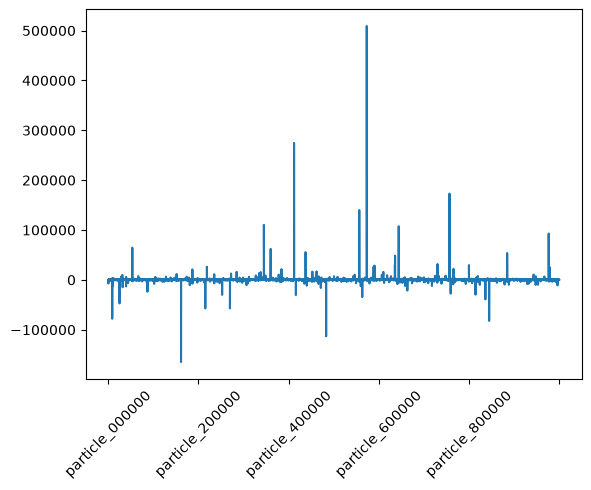

In [69]:
tg_theta.plot()
plt.xticks(rotation=45);

In [70]:
# преобразование фурье ???

<Axes: ylabel='Frequency'>

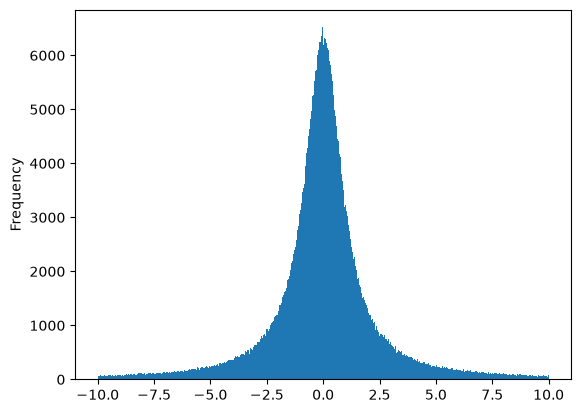

In [79]:
tg_theta[(tg_theta < 10) & (tg_theta > -10)].plot(kind="hist", bins=1000)

In [90]:
df_shorten = df[(tg_theta > 2.5) & (tg_theta < 5.0)]
df_shorten["energy_category"] = df_shorten["p"].apply(
    lambda p: "high" if p > 1.35 else "low" if p < 1.1 else "medium"
)
df_shorten.head(10)

,x,y,p,energy_category
particle_000012,0.343733,1.168115,1.217639,medium
particle_000019,0.369944,1.093992,1.154849,medium
particle_000023,-0.488257,-1.287791,1.377243,high
particle_000034,-0.371931,-0.972756,1.041435,low
particle_000052,0.325227,1.322705,1.362102,high
particle_000059,-0.410891,-1.258090,1.323489,medium
particle_000062,-0.446074,-1.224519,1.303238,medium
particle_000108,-0.363765,-0.934111,1.002441,low
particle_000113,-0.340318,-0.980265,1.037659,low
particle_000118,-0.313507,-1.271477,1.309558,medium


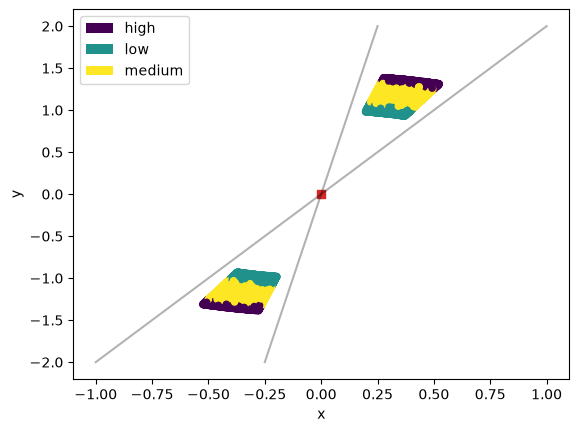

In [107]:
df_shorten.plot.scatter(x="x", y="y", c="energy_category")
plt.plot([-1, 1], [-2, 2], color="black", alpha=0.3);
plt.plot([-0.25, 0.25], [-2, 2], color="black", alpha=0.3);
plt.scatter(0, 0, marker="s", color="C3")

<Axes: xlabel='x', ylabel='y'>

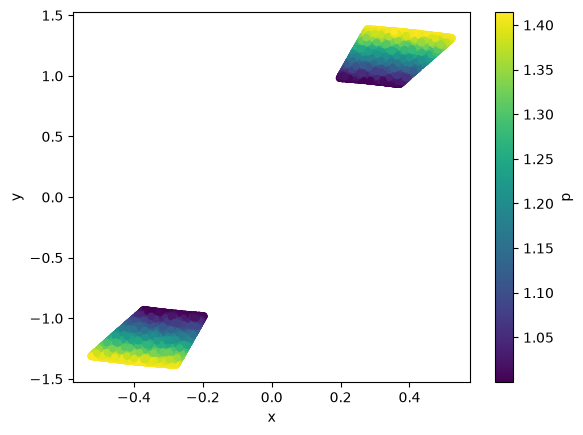

In [96]:
df_shorten.plot.scatter(x="x", y="y", c="p")

In [115]:
df_shorten.describe()
# проценты - квантиль

,x,y,p
count,59021.000000,59021.000000,59021.000000
mean,-0.000632,-0.002624,1.219890
std,0.354428,1.173340,0.119149
min,-0.524012,-1.386527,1.000011
25%,-0.344212,-1.174273,1.118771
50%,-0.204598,-0.940152,1.226354
75%,0.343888,1.172780,1.324136
max,0.523198,1.385511,1.414212


In [121]:
df_shorten.groupby(by=["energy_category"]).agg({"x": "mean", "y": "min", "p": sum}).reset_index()
# в рамках каждой категории подсчитана соотв функция для каждого столба (среднее иксов, min игреков и сумма импульсов)

,energy_category,x,y,p
0,high,0.000264,-1.386527,14605.247971
1,low,0.000078,-1.077851,12924.102539
2,medium,-0.001135,-1.322978,44469.785848


In [116]:
df_shorten.info()

<class 'pandas.DataFrame'>
Index: 59021 entries, particle_000012 to particle_999972
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   x                59021 non-null  float64
 1   y                59021 non-null  float64
 2   p                59021 non-null  float64
 3   energy_category  59021 non-null  str    
dtypes: float64(3), str(1)
memory usage: 4.3+ MB


In [110]:
df = pd.read_csv("http://python.mipt.ru/lpr/extra/lab08/telecom_churn.csv")
# df.to_csv("local.csv")
df

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3328,AZ,192,415,No,Yes,36,156.2,77,26.55,215.5,126,18.32,279.1,83,12.56,9.9,6,2.67,2,False
3329,WV,68,415,No,No,0,231.1,57,39.29,153.4,55,13.04,191.3,123,8.61,9.6,4,2.59,3,False
3330,RI,28,510,No,No,0,180.8,109,30.74,288.8,58,24.55,191.9,91,8.64,14.1,6,3.81,2,False
3331,CT,184,510,Yes,No,0,213.8,105,36.35,159.6,84,13.57,139.2,137,6.26,5.0,10,1.35,2,False


In [111]:
%pip install openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]1/2 [openpyxl]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [112]:
df.to_dict(orient="list")

{'State': ['KS',
  'OH',
  'NJ',
  'OH',
  'OK',
  'AL',
  'MA',
  'MO',
  'LA',
  'WV',
  'IN',
  'RI',
  'IA',
  'MT',
  'IA',
  'NY',
  'ID',
  'VT',
  'VA',
  'TX',
  'FL',
  'CO',
  'AZ',
  'SC',
  'VA',
  'NE',
  'WY',
  'MT',
  'MO',
  'HI',
  'IL',
  'NH',
  'LA',
  'AZ',
  'OK',
  'GA',
  'AK',
  'MA',
  'AK',
  'NJ',
  'GA',
  'MD',
  'AR',
  'ID',
  'WI',
  'OR',
  'MI',
  'DE',
  'ID',
  'WY',
  'IA',
  'IN',
  'VA',
  'UT',
  'WY',
  'IN',
  'CO',
  'CO',
  'WI',
  'OK',
  'ID',
  'CA',
  'MN',
  'SD',
  'NC',
  'WA',
  'WY',
  'MN',
  'UT',
  'TX',
  'NJ',
  'MN',
  'NM',
  'NV',
  'HI',
  'MN',
  'DC',
  'NY',
  'MN',
  'MD',
  'WV',
  'OR',
  'CO',
  'GA',
  'TX',
  'VT',
  'IN',
  'WV',
  'KY',
  'NJ',
  'DC',
  'LA',
  'AR',
  'ME',
  'AZ',
  'AK',
  'MT',
  'AZ',
  'MS',
  'ID',
  'IA',
  'MA',
  'VT',
  'KY',
  'IN',
  'AZ',
  'MI',
  'NM',
  'CO',
  'UT',
  'MI',
  'MA',
  'AL',
  'DE',
  'AZ',
  'ME',
  'NJ',
  'NV',
  'MO',
  'ID',
  'NE',
  'TX',
  'MD',
  'MS',

In [113]:
df.to_dict(orient="index")

{0: {'State': 'KS',
  'Account length': 128,
  'Area code': 415,
  'International plan': 'No',
  'Voice mail plan': 'Yes',
  'Number vmail messages': 25,
  'Total day minutes': 265.1,
  'Total day calls': 110,
  'Total day charge': 45.07,
  'Total eve minutes': 197.4,
  'Total eve calls': 99,
  'Total eve charge': 16.78,
  'Total night minutes': 244.7,
  'Total night calls': 91,
  'Total night charge': 11.01,
  'Total intl minutes': 10.0,
  'Total intl calls': 3,
  'Total intl charge': 2.7,
  'Customer service calls': 1,
  'Churn': False},
 1: {'State': 'OH',
  'Account length': 107,
  'Area code': 415,
  'International plan': 'No',
  'Voice mail plan': 'Yes',
  'Number vmail messages': 26,
  'Total day minutes': 161.6,
  'Total day calls': 123,
  'Total day charge': 27.47,
  'Total eve minutes': 195.5,
  'Total eve calls': 103,
  'Total eve charge': 16.62,
  'Total night minutes': 254.4,
  'Total night calls': 103,
  'Total night charge': 11.45,
  'Total intl minutes': 13.7,
  'Total 

In [1]:
import ROOT